# Proyecto final — Modelos y Simulación II

**Universidad de Antioquia · Facultad de Ingeniería**

- **Equipo:** Samuel Puerta Patiño, Simón Berrio Gaviria, Juan Estiven Carmona Muñoz
- **Grupo:** 5 · **Semestre:** 2026-2
- **Dataset:** *Financial Transactions & Fraud Detection* (Kaggle)

## Protocolo temporal y probabilidades de historial (asesoría con el profesor)

Este notebook incorpora las recomendaciones de la asesoría con el profesor Julián. Complementa los notebooks 01 a 06 y **pasa el esquema temporal a protocolo principal**.

| ID | Recomendación | Dónde se aborda |
|---|---|---|
| R1, R6 | Serie temporal; no usar particiones aleatorias | §3 (partición única y *backtesting* mensual), §4 (comparación con la aleatoria) |
| R2 | Anomalías de uso respecto al historial del usuario | §1 y §5 |
| R3 | Moneda inusual (SOL frente a USD) | §1.3 (documentación) y §6 (control positivo simulado) |
| R4 | Probabilidades 0–1 de frecuencia en el historial, sin la propia transacción | §1 |
| R5 | No descartar ninguna variable | §2 y §7 |
| R7 | Isolation Forest y One-Class SVM | §5 |
| R8 | Con y sin `risk_score` | todo el notebook |

### Decisiones sobre los puntos ambiguos

1. **No se descartan variables.** El modelo final recibe todas; el análisis de reducción de los notebooks 05 y 06 queda como resultado complementario.
2. **`currency` se documenta y se usa.** Solo toma el valor USD, así que su probabilidad es constante (1,0). Se incluye para cumplir con «no descartar» y la §6 muestra con un control positivo simulado que el método sí detectaría una moneda nueva.
3. **Se prueban las dos estrategias temporales:** partición única 80/20 y *backtesting* mensual (febrero a agosto de 2026).
4. **El historial usa toda la historia previa** como opción principal, y se compara con una **ventana de 30 días**.

> **Garantía causal.** Toda variable de historial de una transacción se calcula solo con transacciones **anteriores**. La §1.2 lo verifica empíricamente.

## 0. Configuración

In [2]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold

sys.path.insert(0, "../src")
import protocolo_temporal as P

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42
FIG_DIR = Path("../report/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
COLORES = ["#52514e", "#2a78d6", "#eb6834", "#1baf7a"]
COLOR_REF = "#52514e"


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

## 1. Probabilidades de historial (R2, R3, R4)

Para cada transacción y cada atributo (`category`, `device_type`, `payment_method`, `account_type`, `currency` y la franja horaria) se calcula

$$p=\frac{n_v+m\,p_{\text{global}}}{n+m},$$

donde $n$ es el número de transacciones **previas** del usuario, $n_v$ cuántas de ellas tuvieron el mismo valor que la actual, $p_{\text{global}}$ la frecuencia global previa del valor (suavizada con Laplace usando solo los valores vistos hasta ese momento) y $m=2$ pseudo-transacciones de contracción (como en el notebook 01, porque cada usuario tiene en promedio 4,7 transacciones). El resultado está en $[0,1]$: un valor nunca visto por el usuario tiene probabilidad cercana a 0.

Además se construyen:

- **Probabilidad 0–1 del monto:** p-valor bilateral de $z$ (normal sobre `log(1+amount)`, contraída al perfil global).
- **Combinaciones:** dispositivo × medio de pago, categoría × dispositivo y cuenta × medio de pago.
- **Resúmenes:** `p_min` (la probabilidad más baja) y `n_raros` (cuántos atributos tienen $p<0{,}1$).
- **Recencia:** `log(1 + horas)` desde que el usuario usó por última vez ese valor (solo historia completa).
- **Versión con ventana:** las mismas probabilidades con los últimos 30 días del usuario (sufijo `_w30`).

In [4]:
base = P.cargar_datos("..")
df = P.construir_todo(base, ventana_dias=30)
Y = df["is_fraud"].to_numpy()
print(f"Transacciones: {len(df):,} | Fraudes: {Y.sum()} ({100 * Y.mean():.2f} %) | "
      f"Periodo: {df['timestamp'].min():%Y-%m-%d} a {df['timestamp'].max():%Y-%m-%d}")
VARS_P = [c for c in df.columns if c.startswith(("p_", "n_raros", "rec_"))]
print(f"Variables nuevas de historial: {len(VARS_P)}")
df[VARS_P].describe().T[["count", "mean", "std", "min", "max"]]

Transacciones: 10,000 | Fraudes: 126 (1.26 %) | Periodo: 2025-08-26 a 2026-08-26
Variables nuevas de historial: 29


,count,mean,std,min,max
p_category,"10,000.000",0.155,0.125,0.007,1.000
rec_category,"2,903.000",7.372,1.175,0.449,9.054
p_device_type,"10,000.000",0.379,0.223,0.012,1.000
rec_device_type,"5,000.000",7.075,1.239,0.394,9.043
p_payment_method,"10,000.000",0.296,0.160,0.015,1.000
rec_payment_method,"4,540.000",7.216,1.212,1.174,9.065
p_account_type,"10,000.000",0.382,0.170,0.021,1.000
rec_account_type,"5,287.000",7.147,1.194,0.394,9.043
p_currency,"10,000.000",0.999,0.006,0.667,1.000
p_franja,"10,000.000",0.244,0.122,0.038,1.000


### 1.2 Verificación causal

Si las variables solo miran el pasado, recalcularlas con una base **truncada** (solo las primeras 6.000 transacciones) debe dar exactamente los mismos valores para esas filas.

In [6]:
recortada = P.construir_todo(base.iloc[:6000].reset_index(drop=True), ventana_dias=30)
dif = 0.0
for c in VARS_P:
    a, b = recortada[c].to_numpy(), df[c].iloc[:6000].to_numpy()
    assert (np.isnan(a) == np.isnan(b)).all(), f"{c}: distinto patrón de vacíos al truncar"
    dif = max(dif, np.nanmax(np.abs(a - b)))
print(f"Máxima diferencia al truncar el futuro: {dif:.2e}")
assert dif < 1e-9, "alguna variable usa información futura"

Máxima diferencia al truncar el futuro: 0.00e+00


### 1.3 `currency` (R3): documentación

En esta base hay **una sola moneda**, así que la hipótesis del profesor **no puede evaluarse con datos reales**. `p_currency` se calcula igual que las demás y se incluye en los modelos, pero es constante. La §6 demuestra con una anomalía simulada que el método detectaría una moneda nueva.

In [8]:
print("Valores distintos de currency:", base["currency"].value_counts().to_dict())
print("Valores distintos de p_currency:", df["p_currency"].unique(), "| de p_currency_w30:", df["p_currency_w30"].unique())

Valores distintos de currency: {'USD': 10000}
Valores distintos de p_currency: [1.         0.66666667 0.75       ... 0.99998    0.99997778 0.99998   ] | de p_currency_w30: [1.         0.66666667 0.75       ... 0.99989999 0.9999     0.99995   ]


### 1.4 Señal individual de cada variable nueva

AUC univariada frente a `is_fraud` (para las `p_*` se usa $-p$: «más raro» debería ser «más fraudulento») con IC bootstrap al 95 %. Son ~27 variables, así que se esperan uno o dos «positivos» por azar; solo un IC que excluya 0,5 de forma clara, y que persista en el protocolo temporal, sería evidencia.

,AUC,inf,sup,nota,"IC excluye 0,5"
variable,,,,,
rec_device_type,0.533,0.484,0.582,,False
rec_franja,0.531,0.487,0.576,,False
p_account_type_w30,0.524,0.468,0.570,,False
p_cuenta_metodo,0.522,0.467,0.566,,False
p_payment_method,0.516,0.466,0.562,,False
p_cuenta_metodo_w30,0.515,0.467,0.558,,False
p_account_type,0.515,0.462,0.561,,False
p_monto_w30,0.509,0.463,0.557,,False
p_franja_w30,0.505,0.458,0.561,,False


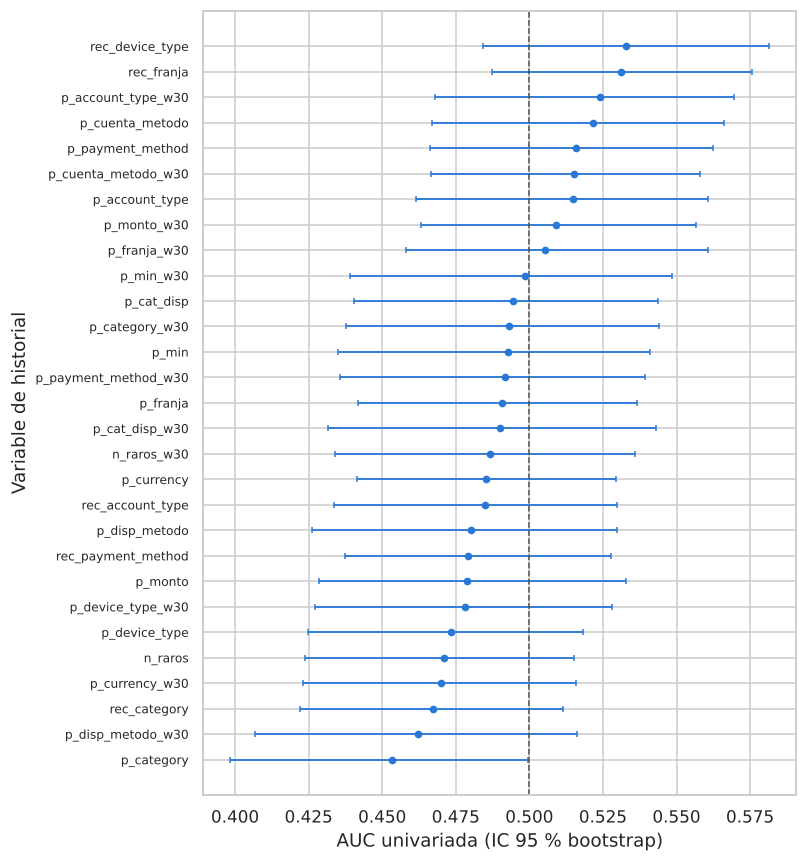

In [10]:
filas = []
for c in VARS_P:
    x = df[c]
    if x.nunique() < 2:
        filas.append({"variable": c, "AUC": np.nan, "inf": np.nan, "sup": np.nan, "nota": "constante"})
        continue
    x = x.fillna(x.median()).to_numpy()
    sgn = -x if c.startswith("p_") else x
    a = roc_auc_score(Y, sgn)
    lo, hi = P.bootstrap_ic(Y, sgn, roc_auc_score, replicas=500)
    filas.append({"variable": c, "AUC": a, "inf": lo, "sup": hi, "nota": ""})
auc_uni = pd.DataFrame(filas).set_index("variable")
auc_uni["IC excluye 0,5"] = (auc_uni["inf"] > 0.5) | (auc_uni["sup"] < 0.5)
display(auc_uni.sort_values("AUC", ascending=False))

t = auc_uni.dropna(subset=["AUC"]).sort_values("AUC")
fig, ax = plt.subplots(figsize=(7.5, 8))
ax.errorbar(t["AUC"], range(len(t)), xerr=[t["AUC"] - t["inf"], t["sup"] - t["AUC"]], fmt="o", ms=4, lw=1.2, color=COLORES[1], capsize=2)
ax.axvline(0.5, color=COLOR_REF, ls="--", lw=1)
ax.set_yticks(range(len(t)), t.index, fontsize=8)
ax.set_xlabel("AUC univariada (IC 95 % bootstrap)")
ax.set_ylabel("Variable de historial")
savefig("fig07_auc_univariada")
plt.show()

*Figura 1. AUC univariada de cada variable de historial frente a `is_fraud`, con IC al 95 %. La línea discontinua es el azar (0,5).*

## 2. Conjuntos de variables (R5, R8)

Ningún conjunto descarta variables: cada uno **añade** al anterior. Se evalúa cada uno **sin** y **con** `risk_score` (R8).

| Conjunto | Contenido |
|---|---|
| **B0 base** | Variables originales y de caracterización del notebook 01 |
| **B1 +historial completo** | B0 + probabilidades 0–1 con toda la historia previa + recencia |
| **B2 +ventana 30 d** | B0 + probabilidades 0–1 con los últimos 30 días + recencia |
| **B3 +ambas** | B0 + historia completa + ventana 30 d |

Cada uno tiene una versión «+ risk» con `risk_score`.

In [13]:
SETS = P.conjuntos(df, ventana_dias=30)
filas = {}
for nombre, spec in SETS.items():
    Xt = P.preprocesador(spec).fit(df[P.cols(spec)]).transform(df[P.cols(spec)].head(50))
    filas[nombre] = {"variables de entrada": len(P.cols(spec)), "columnas tras codificar": Xt.shape[1]}
pd.DataFrame(filas).T

,variables de entrada,columnas tras codificar
B0 base,21,36
B0 base + risk,22,37
B1 +historial completo,38,53
B1 +historial completo + risk,39,54
B2 +ventana 30 d,38,53
B2 +ventana 30 d + risk,39,54
B3 +ambas,50,65
B3 +ambas + risk,51,66


## 3. Protocolo temporal (R1, R6)

Se evalúan los seis modelos de la guía (regresión logística, KNN, Random Forest balanceado, gradient boosting, red neuronal y SVM RBF). Los hiperparámetros se ajustan con **validación cruzada temporal expansiva**: el periodo de ajuste se divide en bloques cronológicos y en cada partición se entrena con los bloques 1..k y se valida con el k+1. **Nunca se mezcla pasado y futuro y no se estratifica.**

- **Estrategia 1 — partición única 80/20.** Ajuste con el 80 % más antiguo, prueba con el 20 % más reciente.
- **Estrategia 2 — *backtesting* mensual.** Hiperparámetros ajustados **solo con datos anteriores a febrero de 2026**; luego, para cada mes de febrero a agosto, se reentrena con todo lo anterior y se predice el mes. Los puntajes de cada ventana se convierten a rango percentil antes de juntarlos, porque cada reentrenamiento tiene su propia escala.

### 3.1 Tamaños y potencia

In [15]:
CORTE = int(0.8 * len(df))
IDX_TR, IDX_TE = np.arange(CORTE), np.arange(CORTE, len(df))
INICIO_BT = pd.Timestamp("2026-02-01")
IDX_PRE = np.flatnonzero((df["timestamp"] < INICIO_BT).to_numpy())
VENT = P.ventanas_mensuales(df)
IDX_BT = np.concatenate([i for _, i in VENT])

filas = [
    ("Estrategia 1: ajuste (80 % más antiguo)", len(IDX_TR), Y[IDX_TR].sum(), f"hasta {df['timestamp'].iloc[CORTE - 1]:%Y-%m-%d}"),
    ("Estrategia 1: prueba (20 % más reciente)", len(IDX_TE), Y[IDX_TE].sum(), f"desde {df['timestamp'].iloc[CORTE]:%Y-%m-%d}"),
    ("Estrategia 2: ajuste (antes de feb-2026)", len(IDX_PRE), Y[IDX_PRE].sum(), "hasta 2026-01-31"),
    ("Estrategia 2: backtesting (feb-ago 2026)", len(IDX_BT), Y[IDX_BT].sum(), f"{len(VENT)} ventanas mensuales"),
]
tam = pd.DataFrame(filas, columns=["conjunto", "transacciones", "fraudes", "periodo"]).set_index("conjunto")
tam["AUC mínima detectable (potencia 0,8; α = 0,05)"] = [P.auc_minima_detectable(f, n - f) for n, f in zip(tam["transacciones"], tam["fraudes"])]
display(tam)
print("Fraudes por ventana mensual:", {str(m): int(Y[i].sum()) for m, i in VENT})
print("Fraudes en cada partición de la CV temporal (estrategia 1):",
      [int(Y[va].sum()) for _, va in P.folds_expansivos(IDX_TR, 6, 2)], "| (estrategia 2):",
      [int(Y[va].sum()) for _, va in P.folds_expansivos(IDX_PRE, 5, 2)])

Fraudes por ventana mensual: {'2026-02': 8, '2026-03': 9, '2026-04': 11, '2026-05': 14, '2026-06': 12, '2026-07': 10, '2026-08': 7}
Fraudes en cada partición de la CV temporal (estrategia 1): [21, 13, 15, 21] | (estrategia 2): [14, 15, 11]


,transacciones,fraudes,periodo,"AUC mínima detectable (potencia 0,8; α = 0,05)"
conjunto,,,,
Estrategia 1: ajuste (80 % más antiguo),8000,102,hasta 2026-06-14,0.581
Estrategia 1: prueba (20 % más reciente),2000,24,desde 2026-06-14,0.666
Estrategia 2: ajuste (antes de feb-2026),4284,55,hasta 2026-01-31,0.610
Estrategia 2: backtesting (feb-ago 2026),5716,71,7 ventanas mensuales,0.597


La prueba de la estrategia 1 tiene pocos fraudes, así que **solo detectaría efectos grandes**. El *backtesting* junta más fraudes de prueba y por eso es la estimación principal; la AUC mínima detectable es una aproximación normal (error estándar bajo H₀ de Hanley y McNeil).

### 3.2 Estrategia 1: ajuste de hiperparámetros y prueba

In [17]:
MODELOS = list(P.MODELOS)
mejores1, tablas1 = {}, {}
t0 = time.time()
for nombre_set, spec in SETS.items():
    for m in MODELOS:
        mejores1[(nombre_set, m)], tablas1[(nombre_set, m)] = P.ajustar_hiperparametros(m, spec, df, IDX_TR, n_bloques=6, primer=2)
    print(f"{nombre_set}: listo ({time.time() - t0:.0f} s acumulados)")

B0 base: listo (71 s acumulados)
B0 base + risk: listo (138 s acumulados)
B1 +historial completo: listo (222 s acumulados)
B1 +historial completo + risk: listo (306 s acumulados)
B2 +ventana 30 d: listo (392 s acumulados)
B2 +ventana 30 d + risk: listo (477 s acumulados)
B3 +ambas: listo (575 s acumulados)
B3 +ambas + risk: listo (669 s acumulados)


In [18]:
filas = []
for (nombre_set, m), params in mejores1.items():
    s = P.ajustar_y_puntuar(m, SETS[nombre_set], df.iloc[IDX_TR], df.iloc[IDX_TE], **params)
    lo, hi = P.bootstrap_ic(Y[IDX_TE], s, average_precision_score, replicas=500)
    filas.append({"conjunto": nombre_set, "modelo": m, **P.metricas(Y[IDX_TE], s), "pr_auc_inf": lo, "pr_auc_sup": hi,
                  "val_pr_auc": tablas1[(nombre_set, m)]["pr_auc_media"].max()})
res1 = pd.DataFrame(filas)

s_rs = df["risk_score"].to_numpy()[IDX_TE]
ic_rs = P.bootstrap_ic(Y[IDX_TE], s_rs, average_precision_score, replicas=500)
ref1 = {**P.metricas(Y[IDX_TE], s_rs), "pr_auc_inf": ic_rs[0], "pr_auc_sup": ic_rs[1]}
print(f"Azar (tasa de fraude en la prueba): PR-AUC = {Y[IDX_TE].mean():.4f}")
print("risk_score sin modelo: PR-AUC = {pr_auc:.3f} [{pr_auc_inf:.3f}, {pr_auc_sup:.3f}] | ROC-AUC = {roc_auc:.3f} | Recall@2 % = {recall_2pct:.3f}".format(**ref1))
print("\nPR-AUC en la prueba (estrategia 1)")
res1.pivot(index="modelo", columns="conjunto", values="pr_auc").loc[MODELOS][list(SETS)]

Azar (tasa de fraude en la prueba): PR-AUC = 0.0120
risk_score sin modelo: PR-AUC = 0.087 [0.023, 0.255] | ROC-AUC = 0.588 | Recall@2 % = 0.208

PR-AUC en la prueba (estrategia 1)


conjunto,B0 base,B0 base + risk,B1 +historial completo,B1 +historial completo + risk,B2 +ventana 30 d,B2 +ventana 30 d + risk,B3 +ambas,B3 +ambas + risk
modelo,,,,,,,,
Regresión logística,0.013,0.065,0.011,0.029,0.013,0.069,0.013,0.024
KNN,0.015,0.035,0.019,0.015,0.017,0.023,0.016,0.014
Random Forest balanceado,0.025,0.081,0.014,0.099,0.018,0.059,0.016,0.089
Gradient boosting,0.021,0.049,0.011,0.033,0.019,0.047,0.021,0.085
Red neuronal (MLP),0.011,0.016,0.018,0.028,0.014,0.046,0.013,0.020
SVM (RBF),0.016,0.029,0.014,0.021,0.018,0.030,0.016,0.023


In [19]:
print("PR-AUC media de validación temporal (mejor configuración de cada modelo)")
display(res1.pivot(index="modelo", columns="conjunto", values="val_pr_auc").loc[MODELOS][list(SETS)])
print("Hiperparámetros elegidos (conjunto B3 + risk)")
pd.Series({m: mejores1[("B3 +ambas + risk", m)] for m in MODELOS}).to_frame("hiperparámetros")

PR-AUC media de validación temporal (mejor configuración de cada modelo)
Hiperparámetros elegidos (conjunto B3 + risk)


conjunto,B0 base,B0 base + risk,B1 +historial completo,B1 +historial completo + risk,B2 +ventana 30 d,B2 +ventana 30 d + risk,B3 +ambas,B3 +ambas + risk
modelo,,,,,,,,
Regresión logística,0.020,0.075,0.020,0.033,0.024,0.038,0.023,0.035
KNN,0.020,0.045,0.025,0.038,0.044,0.042,0.024,0.048
Random Forest balanceado,0.017,0.170,0.020,0.165,0.039,0.184,0.027,0.157
Gradient boosting,0.023,0.154,0.023,0.171,0.022,0.122,0.023,0.123
Red neuronal (MLP),0.018,0.025,0.019,0.032,0.022,0.021,0.021,0.028
SVM (RBF),0.019,0.064,0.031,0.049,0.034,0.055,0.029,0.058


,hiperparámetros
Regresión logística,{'C': 0.001}
KNN,"{'n_neighbors': 51, 'sampling_strategy': 0.1}"
Random Forest balanceado,"{'max_features': 0.5, 'min_samples_leaf': 5}"
Gradient boosting,"{'learning_rate': 0.03, 'max_depth': 4}"
Red neuronal (MLP),"{'alpha': 0.001, 'hidden_layer_sizes': (32, 16)}"
SVM (RBF),"{'C': 0.1, 'gamma': 0.01}"


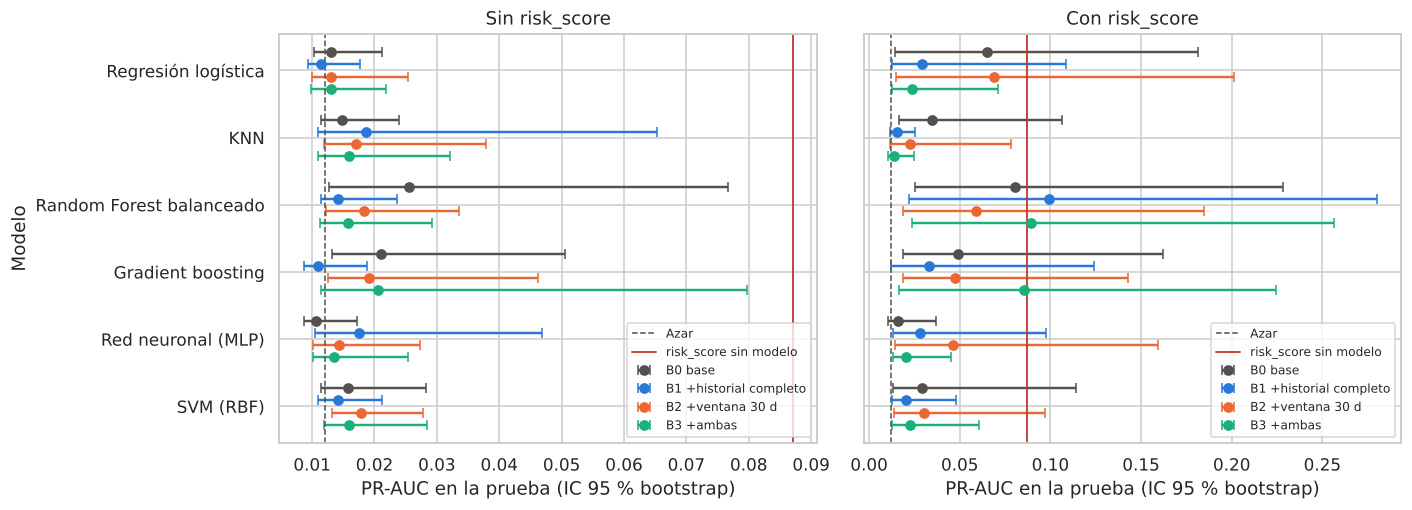

In [20]:
def figura_pr(res, ic, nombre, titulo_eje):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
    for ax, con_risk in zip(axes, (False, True)):
        nombres = [n for n in SETS if n.endswith("+ risk") == con_risk]
        for j, (n, color) in enumerate(zip(nombres, COLORES)):
            t = res[res["conjunto"] == n].set_index("modelo").loc[MODELOS]
            pos = np.arange(len(MODELOS)) + (j - 1.5) * 0.18
            ax.errorbar(t["pr_auc"], pos, xerr=[t["pr_auc"] - t["pr_auc_inf"], t["pr_auc_sup"] - t["pr_auc"]],
                        fmt="o", ms=6, lw=1.6, capsize=3, color=color, label=n.replace(" + risk", ""))
        ax.axvline(ic["azar"], color=COLOR_REF, ls="--", lw=1, label="Azar")
        ax.axvline(ic["risk"], color="#c0392b", ls="-", lw=1.2, label="risk_score sin modelo")
        ax.set_yticks(range(len(MODELOS)), MODELOS)
        ax.set_title("Con risk_score" if con_risk else "Sin risk_score")
        ax.set_xlabel(titulo_eje)
        ax.legend(fontsize=8, loc="lower right")
    axes[0].set_ylabel("Modelo")
    axes[0].invert_yaxis()
    savefig(nombre)
    plt.show()


figura_pr(res1, {"azar": Y[IDX_TE].mean(), "risk": ref1["pr_auc"]}, "fig07_estrategia1", "PR-AUC en la prueba (IC 95 % bootstrap)")

*Figura 2. Estrategia 1 (partición temporal 80/20): PR-AUC en el 20 % más reciente para los seis modelos y los cuatro conjuntos de variables, sin `risk_score` (izquierda) y con `risk_score` (derecha). Barras: IC al 95 % por bootstrap estratificado.*

### 3.3 Estrategia 2: *backtesting* mensual

Hiperparámetros ajustados solo con datos anteriores a febrero de 2026.

In [23]:
mejores2, tablas2 = {}, {}
t0 = time.time()
for nombre_set, spec in SETS.items():
    for m in MODELOS:
        mejores2[(nombre_set, m)], tablas2[(nombre_set, m)] = P.ajustar_hiperparametros(m, spec, df, IDX_PRE, n_bloques=5, primer=2)
    print(f"{nombre_set}: listo ({time.time() - t0:.0f} s acumulados)")

B0 base: listo (28 s acumulados)
B0 base + risk: listo (56 s acumulados)
B1 +historial completo: listo (92 s acumulados)
B1 +historial completo + risk: listo (129 s acumulados)
B2 +ventana 30 d: listo (165 s acumulados)
B2 +ventana 30 d + risk: listo (200 s acumulados)
B3 +ambas: listo (242 s acumulados)
B3 +ambas + risk: listo (285 s acumulados)


In [24]:
def rango_percentil(s):
    return stats.rankdata(s) / len(s)


pred2 = {}
t0 = time.time()
for (nombre_set, m), params in mejores2.items():
    pooled = np.zeros(len(IDX_BT)); pos = 0
    for mes, idx in VENT:
        s = P.ajustar_y_puntuar(m, SETS[nombre_set], df.iloc[np.arange(idx[0])], df.iloc[idx], **params)
        pooled[pos:pos + len(idx)] = rango_percentil(s); pos += len(idx)
    pred2[(nombre_set, m)] = pooled
    if m == MODELOS[-1]:
        print(f"{nombre_set}: listo ({time.time() - t0:.0f} s acumulados)")

Y_BT = Y[IDX_BT]
rs_bt = np.concatenate([rango_percentil(df["risk_score"].to_numpy()[i]) for _, i in VENT])
filas = []
for (nombre_set, m), s in pred2.items():
    lo, hi = P.bootstrap_ic(Y_BT, s, average_precision_score, replicas=500)
    filas.append({"conjunto": nombre_set, "modelo": m, **P.metricas(Y_BT, s), "pr_auc_inf": lo, "pr_auc_sup": hi})
res2 = pd.DataFrame(filas)
ref2 = {**P.metricas(Y_BT, rs_bt)}
ref2["pr_auc_inf"], ref2["pr_auc_sup"] = P.bootstrap_ic(Y_BT, rs_bt, average_precision_score, replicas=500)
print(f"Azar (tasa de fraude en el backtesting): PR-AUC = {Y_BT.mean():.4f}")
print("risk_score sin modelo: PR-AUC = {pr_auc:.3f} [{pr_auc_inf:.3f}, {pr_auc_sup:.3f}] | ROC-AUC = {roc_auc:.3f} | Recall@2 % = {recall_2pct:.3f}".format(**ref2))
print("\nPR-AUC agrupada del backtesting (estrategia 2)")
res2.pivot(index="modelo", columns="conjunto", values="pr_auc").loc[MODELOS][list(SETS)]

B0 base: listo (28 s acumulados)
B0 base + risk: listo (65 s acumulados)
B1 +historial completo: listo (117 s acumulados)
B1 +historial completo + risk: listo (170 s acumulados)
B2 +ventana 30 d: listo (219 s acumulados)
B2 +ventana 30 d + risk: listo (255 s acumulados)
B3 +ambas: listo (313 s acumulados)
B3 +ambas + risk: listo (369 s acumulados)
Azar (tasa de fraude en el backtesting): PR-AUC = 0.0124
risk_score sin modelo: PR-AUC = 0.159 [0.082, 0.271] | ROC-AUC = 0.624 | Recall@2 % = 0.254

PR-AUC agrupada del backtesting (estrategia 2)


conjunto,B0 base,B0 base + risk,B1 +historial completo,B1 +historial completo + risk,B2 +ventana 30 d,B2 +ventana 30 d + risk,B3 +ambas,B3 +ambas + risk
modelo,,,,,,,,
Regresión logística,0.015,0.039,0.014,0.030,0.014,0.029,0.013,0.024
KNN,0.017,0.017,0.020,0.018,0.019,0.019,0.014,0.019
Random Forest balanceado,0.016,0.109,0.014,0.099,0.017,0.122,0.015,0.087
Gradient boosting,0.015,0.083,0.014,0.090,0.012,0.085,0.015,0.089
Red neuronal (MLP),0.012,0.015,0.015,0.019,0.013,0.015,0.014,0.018
SVM (RBF),0.013,0.020,0.015,0.025,0.016,0.020,0.015,0.025


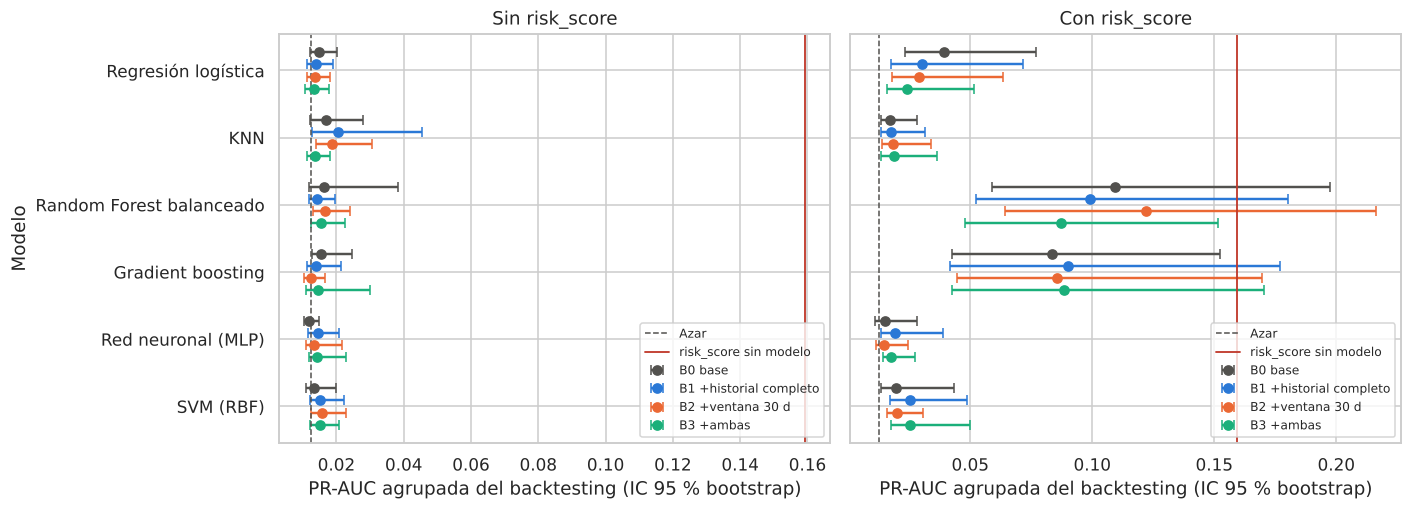

In [25]:
figura_pr(res2, {"azar": Y_BT.mean(), "risk": ref2["pr_auc"]}, "fig07_backtesting", "PR-AUC agrupada del backtesting (IC 95 % bootstrap)")

*Figura 3. Estrategia 2 (backtesting mensual de febrero a agosto de 2026): PR-AUC con los puntajes de las siete ventanas agrupados (rango percentil dentro de cada ventana), para los seis modelos y los cuatro conjuntos de variables. Barras: IC al 95 % por bootstrap estratificado.*

In [27]:
print("ROC-AUC agrupada del backtesting")
display(res2.pivot(index="modelo", columns="conjunto", values="roc_auc").loc[MODELOS][list(SETS)])
print("Recall@2 % del backtesting")
res2.pivot(index="modelo", columns="conjunto", values="recall_2pct").loc[MODELOS][list(SETS)]

ROC-AUC agrupada del backtesting
Recall@2 % del backtesting


conjunto,B0 base,B0 base + risk,B1 +historial completo,B1 +historial completo + risk,B2 +ventana 30 d,B2 +ventana 30 d + risk,B3 +ambas,B3 +ambas + risk
modelo,,,,,,,,
Regresión logística,0.531,0.636,0.524,0.620,0.522,0.628,0.505,0.609
KNN,0.498,0.568,0.518,0.565,0.579,0.581,0.521,0.581
Random Forest balanceado,0.543,0.653,0.552,0.658,0.567,0.653,0.555,0.666
Gradient boosting,0.549,0.620,0.514,0.593,0.499,0.631,0.481,0.604
Red neuronal (MLP),0.488,0.490,0.509,0.548,0.484,0.508,0.539,0.595
SVM (RBF),0.514,0.557,0.547,0.629,0.554,0.623,0.555,0.615


conjunto,B0 base,B0 base + risk,B1 +historial completo,B1 +historial completo + risk,B2 +ventana 30 d,B2 +ventana 30 d + risk,B3 +ambas,B3 +ambas + risk
modelo,,,,,,,,
Regresión logística,0.000,0.141,0.014,0.070,0.000,0.085,0.000,0.042
KNN,0.070,0.042,0.070,0.056,0.085,0.056,0.000,0.028
Random Forest balanceado,0.014,0.254,0.014,0.239,0.028,0.254,0.028,0.254
Gradient boosting,0.028,0.211,0.056,0.239,0.014,0.225,0.028,0.211
Red neuronal (MLP),0.000,0.028,0.014,0.042,0.042,0.028,0.028,0.042
SVM (RBF),0.028,0.056,0.042,0.070,0.028,0.042,0.028,0.085


### 3.4 ¿Historia completa o ventana de 30 días? (punto 4 de la asesoría)

Promedio de los seis modelos del efecto de cada forma de construir el historial, **sin** y **con** `risk_score`.

In [29]:
def resumen_sets(res):
    return res.groupby("conjunto")[["pr_auc", "roc_auc", "recall_2pct"]].mean().loc[list(SETS)]

print("Estrategia 1 (prueba 20 %): promedio de los 6 modelos")
display(resumen_sets(res1))
print("Estrategia 2 (backtesting): promedio de los 6 modelos")
resumen_sets(res2)

Estrategia 1 (prueba 20 %): promedio de los 6 modelos
Estrategia 2 (backtesting): promedio de los 6 modelos


,pr_auc,roc_auc,recall_2pct
conjunto,,,
B0 base,0.017,0.529,0.021
B0 base + risk,0.046,0.607,0.111
B1 +historial completo,0.014,0.499,0.021
B1 +historial completo + risk,0.038,0.573,0.076
B2 +ventana 30 d,0.017,0.552,0.028
B2 +ventana 30 d + risk,0.046,0.587,0.111
B3 +ambas,0.016,0.523,0.007
B3 +ambas + risk,0.043,0.575,0.097


,pr_auc,roc_auc,recall_2pct
conjunto,,,
B0 base,0.015,0.520,0.023
B0 base + risk,0.047,0.587,0.122
B1 +historial completo,0.015,0.527,0.035
B1 +historial completo + risk,0.047,0.602,0.120
B2 +ventana 30 d,0.015,0.534,0.033
B2 +ventana 30 d + risk,0.048,0.604,0.115
B3 +ambas,0.014,0.526,0.019
B3 +ambas + risk,0.044,0.612,0.110


## 4. ¿La partición aleatoria y la temporal dan lo mismo?

El profesor pidió no usar particiones aleatorias. En el notebook 03 se justificó la aleatoria porque los fraudes llegan sin tendencia. Aquí se **comprueba**: para B1 sin y con `risk_score` se repite cada modelo (con los hiperparámetros de la estrategia 1) bajo validación cruzada estratificada aleatoria 5 × 2 sobre toda la base. Las poblaciones de prueba no son idénticas, así que es una comparación de magnitud, no una prueba pareada.

In [ ]:
CV_ALEATORIA = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)
particiones = list(CV_ALEATORIA.split(df, Y))
filas = []
t0 = time.time()
for nombre_set in ["B1 +historial completo", "B1 +historial completo + risk"]:
    for m in MODELOS:
        vals = []
        for tr, te in particiones:
            s = P.ajustar_y_puntuar(m, SETS[nombre_set], df.iloc[tr], df.iloc[te], **mejores1[(nombre_set, m)])
            vals.append(average_precision_score(Y[te], s))
        v1 = res1[(res1.conjunto == nombre_set) & (res1.modelo == m)]["pr_auc"].iloc[0]
        v2 = res2[(res2.conjunto == nombre_set) & (res2.modelo == m)]["pr_auc"].iloc[0]
        filas.append({"conjunto": nombre_set, "modelo": m, "aleatoria 5x2": np.mean(vals), "sd": np.std(vals, ddof=1),
                      "temporal 80/20": v1, "backtesting": v2})
    print(f"{nombre_set}: listo ({time.time() - t0:.0f} s acumulados)")
comp = pd.DataFrame(filas).set_index(["conjunto", "modelo"])
print(f"Azar: {Y.mean():.4f} (completa) | {Y[IDX_TE].mean():.4f} (prueba 20 %) | {Y_BT.mean():.4f} (backtesting)")
comp

## 5. Detección de anomalías sobre las probabilidades de historial (R7)

Se entrenan **Isolation Forest** y **One-Class SVM** (se leyó «OJVM» como One-Class SVM; por confirmar con el profesor) solo con transacciones **normales** del periodo de ajuste. Cada transacción posterior es más sospechosa cuanto más atípicas sean sus probabilidades de historial. Espacios:

- **P completo:** todas las `p_*` de historia completa (incluye `p_currency`, constante).
- **P ventana 30 d:** todas las `p_*_w30`.
- **P completo + risk_score.**
- **Solo risk_score** (referencia).

Se aplica con las dos estrategias temporales.

In [ ]:
P_FULL = [c for c in df.columns if c.startswith("p_") and not c.endswith("_w30") and c != "p_min"]
P_W30 = [c for c in df.columns if c.startswith("p_") and c.endswith("_w30") and c != "p_min_w30"]
ESPACIOS = {"P completo": P_FULL, "P ventana 30 d": P_W30, "P completo + risk_score": P_FULL + ["risk_score"], "Solo risk_score": ["risk_score"]}
DET = P.detectores()
Z = df.copy()
Z["risk_score"] = Z["risk_score"].astype(float)

filas, filas_bt = [], []
t0 = time.time()
for e, cols_e in ESPACIOS.items():
    X = Z[cols_e].to_numpy(dtype=float)
    for d, fabrica in DET.items():
        norm = IDX_TR[Y[IDX_TR] == 0]
        s = P.puntaje_anomalia(fabrica, X[norm], X[IDX_TE])
        lo, hi = P.bootstrap_ic(Y[IDX_TE], s, average_precision_score, replicas=500)
        filas.append({"espacio": e, "detector": d, "pr_auc": average_precision_score(Y[IDX_TE], s), "pr_auc_inf": lo, "pr_auc_sup": hi,
                      "roc_auc": roc_auc_score(Y[IDX_TE], s)})
        pooled = np.zeros(len(IDX_BT)); pos = 0
        for mes, idx in VENT:
            tr = np.arange(idx[0]); tr = tr[Y[tr] == 0]
            sv = P.puntaje_anomalia(fabrica, X[tr], X[idx]); pooled[pos:pos + len(idx)] = rango_percentil(sv); pos += len(idx)
        lo, hi = P.bootstrap_ic(Y_BT, pooled, average_precision_score, replicas=500)
        filas_bt.append({"espacio": e, "detector": d, "pr_auc": average_precision_score(Y_BT, pooled), "pr_auc_inf": lo, "pr_auc_sup": hi,
                         "roc_auc": roc_auc_score(Y_BT, pooled)})
    print(f"{e}: listo ({time.time() - t0:.0f} s acumulados)")
anom1, anom2 = pd.DataFrame(filas), pd.DataFrame(filas_bt)

print(f"Azar: {Y[IDX_TE].mean():.4f} (estrategia 1) | {Y_BT.mean():.4f} (estrategia 2)")
print("Estrategia 1 (partición 80/20): PR-AUC")
display(anom1.pivot(index="detector", columns="espacio", values="pr_auc")[list(ESPACIOS)])
print("Estrategia 2 (backtesting): PR-AUC")
anom2.pivot(index="detector", columns="espacio", values="pr_auc")[list(ESPACIOS)]

In [ ]:
print("ROC-AUC, estrategia 1")
display(anom1.pivot(index="detector", columns="espacio", values="roc_auc")[list(ESPACIOS)])
print("ROC-AUC, estrategia 2")
display(anom2.pivot(index="detector", columns="espacio", values="roc_auc")[list(ESPACIOS)])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (nombre, t, azar) in zip(axes, [("Estrategia 1: partición 80/20", anom1, Y[IDX_TE].mean()), ("Estrategia 2: backtesting", anom2, Y_BT.mean())]):
    for j, (d, color) in enumerate(zip(DET, COLORES[1:])):
        u = t[t.detector == d].set_index("espacio").loc[list(ESPACIOS)]
        pos = np.arange(len(ESPACIOS)) + (j - 1) * 0.2
        ax.errorbar(u["pr_auc"], pos, xerr=[u["pr_auc"] - u["pr_auc_inf"], u["pr_auc_sup"] - u["pr_auc"]], fmt="o", ms=6, lw=1.6, capsize=3, color=color, label=d)
    ax.axvline(azar, color=COLOR_REF, ls="--", lw=1, label="Azar")
    ax.set_yticks(range(len(ESPACIOS)), list(ESPACIOS))
    ax.set_title(nombre)
    ax.set_xlabel("PR-AUC (IC 95 % bootstrap)")
axes[0].set_ylabel("Espacio de variables")
axes[0].invert_yaxis()
axes[1].legend(fontsize=8, loc="lower right")
savefig("fig07_anomalias")
plt.show()

*Figura 4. Detectores de anomalías de una clase entrenados solo con transacciones normales, sobre las probabilidades de historial. Izquierda: partición temporal 80/20. Derecha: backtesting mensual. La línea discontinua es el azar.*

## 6. Control positivo: ¿el método detectaría una moneda nueva? (R3)

Como la base solo tiene USD, se **simula**: en el 20 % más reciente se toman 100 transacciones al azar de usuarios con al menos 3 transacciones previas y se les cambia la moneda a «SOL». Se recalculan las probabilidades de historial con el mismo procedimiento causal y se mide si `p_currency` y los detectores (entrenados en el periodo de ajuste, que no se toca) separan las inyectadas. Se repite con el **monto multiplicado por 15**. Son anomalías sintéticas: muestran que el método **puede** detectar ese tipo de anomalía, no que ocurra en los datos.

*Observación esperada:* en el periodo de ajuste `p_currency` es constante, así que un Isolation Forest no puede dividir por esa columna y probablemente detecte peor la moneda nueva que la propia `p_currency` usada directamente. Es un hallazgo legítimo sobre la limitación de entrenar con una variable constante.

In [ ]:
def control_positivo(tipo, k=100, semilla=RANDOM_STATE):
    rng = np.random.default_rng(semilla)
    sim = base.copy()
    elegibles = IDX_TE[sim["transacciones_previas"].to_numpy()[IDX_TE] >= 3]
    inyectadas = rng.choice(elegibles, size=k, replace=False)
    if tipo == "moneda":
        sim.loc[inyectadas, "currency"] = "SOL"
    else:
        sim.loc[inyectadas, "amount"] = sim.loc[inyectadas, "amount"] * 15
        sim["amount_log"] = np.log1p(sim["amount"])
    sim = P.construir_todo(sim, ventana_dias=30)
    marca = np.zeros(len(sim), dtype=int); marca[inyectadas] = 1
    cols_e = [c for c in sim.columns if c.startswith("p_") and not c.endswith("_w30") and c != "p_min"]
    X = sim[cols_e].to_numpy(dtype=float)
    norm = IDX_TR[Y[IDX_TR] == 0]
    s_if = P.puntaje_anomalia(DET["Isolation Forest"], X[norm], X[IDX_TE])
    s_oc = P.puntaje_anomalia(DET["One-Class SVM (nu=0,05)"], X[norm], X[IDX_TE])
    col = "p_currency" if tipo == "moneda" else "p_monto"
    return {
        "anomalía simulada": tipo, "inyectadas": k,
        f"AUC de 1 − {col}": roc_auc_score(marca[IDX_TE], 1 - sim[col].to_numpy()[IDX_TE]),
        "AUC Isolation Forest": roc_auc_score(marca[IDX_TE], s_if),
        "AUC One-Class SVM": roc_auc_score(marca[IDX_TE], s_oc),
        f"mediana de {col} (inyectadas)": np.median(sim[col].to_numpy()[inyectadas]),
        f"mediana de {col} (resto)": np.median(sim[col].to_numpy()[np.setdiff1d(IDX_TE, inyectadas)]),
    }

pd.DataFrame([control_positivo("moneda"), control_positivo("monto")]).set_index("anomalía simulada").T

## 7. Modelo final con todas las variables (R5) y resumen

El modelo final **recibe todas las variables** (conjunto B3). Se reportan las dos versiones (sin y con `risk_score`) y se comparan con `risk_score` usado directamente. Entre los seis modelos se selecciona el de mayor PR-AUC de **validación temporal** (no de prueba), para no elegir con los datos de evaluación.

In [ ]:
def mejor_por_validacion(nombre_set):
    v = {m: tablas2[(nombre_set, m)]["pr_auc_media"].max() for m in MODELOS}
    return max(v, key=v.get), v

filas = []
for nombre_set in ["B3 +ambas", "B3 +ambas + risk"]:
    m_sel, v = mejor_por_validacion(nombre_set)
    r = res2[(res2.conjunto == nombre_set) & (res2.modelo == m_sel)].iloc[0]
    filas.append({"conjunto": nombre_set, "modelo elegido (validación)": m_sel, "PR-AUC validación": v[m_sel],
                  "PR-AUC backtesting": r["pr_auc"], "IC 95 %": f"[{r['pr_auc_inf']:.3f}, {r['pr_auc_sup']:.3f}]",
                  "ROC-AUC": r["roc_auc"], "Recall@2 %": r["recall_2pct"], "Precisión@2 %": r["precision_2pct"]})
filas.append({"conjunto": "risk_score sin modelo", "modelo elegido (validación)": "—", "PR-AUC validación": np.nan,
              "PR-AUC backtesting": ref2["pr_auc"], "IC 95 %": f"[{ref2['pr_auc_inf']:.3f}, {ref2['pr_auc_sup']:.3f}]",
              "ROC-AUC": ref2["roc_auc"], "Recall@2 %": ref2["recall_2pct"], "Precisión@2 %": ref2["precision_2pct"]})
filas.append({"conjunto": "Azar", "modelo elegido (validación)": "—", "PR-AUC validación": np.nan, "PR-AUC backtesting": Y_BT.mean(),
              "IC 95 %": "—", "ROC-AUC": 0.5, "Recall@2 %": P.FRACCION_ALERTAS, "Precisión@2 %": Y_BT.mean()})
final = pd.DataFrame(filas).set_index("conjunto")
final

In [ ]:
# Desempeño por ventana mensual de los modelos finales
filas = []
for nombre_set in ["B3 +ambas", "B3 +ambas + risk"]:
    m_sel, _ = mejor_por_validacion(nombre_set)
    pos = 0
    for mes, idx in VENT:
        s = pred2[(nombre_set, m_sel)][pos:pos + len(idx)]; pos += len(idx)
        filas.append({"conjunto": nombre_set, "modelo": m_sel, "ventana": str(mes), "transacciones": len(idx), "fraudes": int(Y[idx].sum()),
                      "PR-AUC": average_precision_score(Y[idx], s), "ROC-AUC": roc_auc_score(Y[idx], s) if Y[idx].sum() else np.nan,
                      "azar": Y[idx].mean()})
por_ventana = pd.DataFrame(filas)
por_ventana.set_index(["conjunto", "ventana"])

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 4))
for nombre_set, color in zip(["B3 +ambas", "B3 +ambas + risk"], [COLORES[2], COLORES[3]]):
    t = por_ventana[por_ventana.conjunto == nombre_set]
    ax.plot(t["ventana"], t["PR-AUC"], "-o", color=color, label=nombre_set)
t0_ = por_ventana[por_ventana.conjunto == "B3 +ambas"]
ax.plot(t0_["ventana"], t0_["azar"], "--", color=COLOR_REF, label="Azar (tasa de fraude)")
ax.set_xlabel("Ventana de prueba (mes)")
ax.set_ylabel("PR-AUC en la ventana")
ax.legend(fontsize=8)
savefig("fig07_por_ventana")
plt.show()

*Figura 5. PR-AUC por ventana mensual del backtesting para el modelo final (todas las variables), sin y con `risk_score`. La línea discontinua es la tasa de fraude de cada ventana (azar). Con ~10 fraudes por ventana, cada punto es muy ruidoso.*

## 8. Conclusiones

Las cifras de esta sección se generan **a partir de las tablas calculadas arriba**, para que el texto no pueda contradecir los resultados. Léalas después de ejecutar el notebook completo y redacte las conclusiones finales con ellas.

In [ ]:
def _linea(res, azar, ref, etiqueta):
    sin = res[~res.conjunto.str.endswith("+ risk")].sort_values("pr_auc", ascending=False).iloc[0]
    con = res[res.conjunto.str.endswith("+ risk")].sort_values("pr_auc", ascending=False).iloc[0]
    print(f"[{etiqueta}] azar = {azar:.3f} | risk_score solo = {ref['pr_auc']:.3f} [{ref['pr_auc_inf']:.3f}, {ref['pr_auc_sup']:.3f}]")
    for nom, r in (("Sin risk_score", sin), ("Con risk_score", con)):
        sep = "el IC excluye el azar" if r["pr_auc_inf"] > azar else "el IC incluye el azar"
        print(f"   {nom}: mejor = {r['modelo']} / {r['conjunto']}: PR-AUC {r['pr_auc']:.3f} [{r['pr_auc_inf']:.3f}, {r['pr_auc_sup']:.3f}] -> {sep}")
    prom = res.assign(rk=res.conjunto.str.endswith("+ risk")).groupby("rk")["pr_auc"].mean()
    print(f"   Promedio de los 6 modelos x 4 conjuntos: sin risk_score {prom[False]:.3f} | con risk_score {prom[True]:.3f}")

_linea(res1, Y[IDX_TE].mean(), ref1, "Estrategia 1: partición 80/20")
_linea(res2, Y_BT.mean(), ref2, "Estrategia 2: backtesting")
print()
for nombre, t, azar in (("Estrategia 1", anom1, Y[IDX_TE].mean()), ("Estrategia 2", anom2, Y_BT.mean())):
    s = t[t.espacio.isin(["P completo", "P ventana 30 d"])].sort_values("pr_auc", ascending=False).iloc[0]
    print(f"Anomalías sobre probabilidades ({nombre}): mejor = {s['detector']} / {s['espacio']}: PR-AUC {s['pr_auc']:.3f} "
          f"[{s['pr_auc_inf']:.3f}, {s['pr_auc_sup']:.3f}] frente a azar {azar:.3f}")
n_sig = int(auc_uni["IC excluye 0,5"].sum())
print(f"\nVariables de historial con IC univariado que excluye 0,5: {n_sig} de {auc_uni['AUC'].notna().sum()} (se esperan ~{0.05 * auc_uni['AUC'].notna().sum():.1f} por azar)")